In [55]:
import numpy as np
import matplotlib.pyplot as plt

In [56]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/Digital image processing/DIP4E/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')
f1.shape+f2.shape

(598, 566, 680, 888)

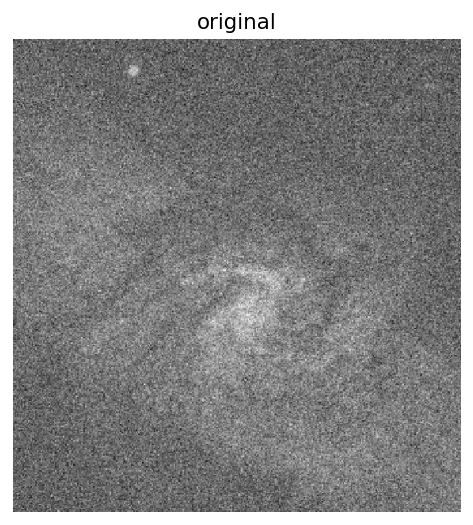

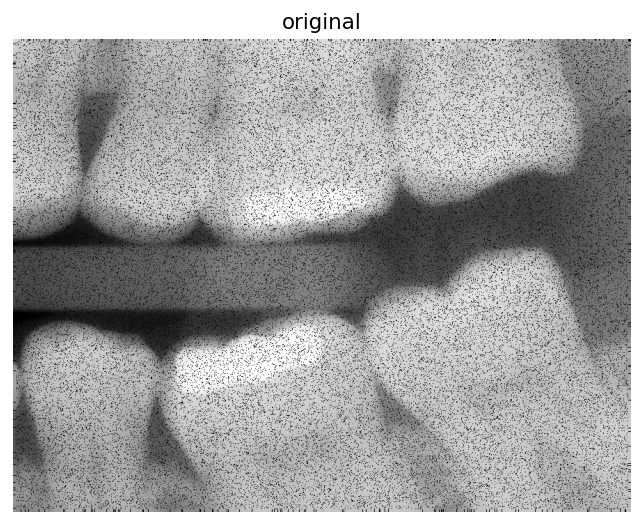

In [58]:
plt.figure(dpi=128)
plt.imshow(f1, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('original')
plt.show()

plt.figure(dpi=128)
plt.imshow(f2, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('original')
plt.show()

In [59]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)

1. Arithmetic Mean Filter

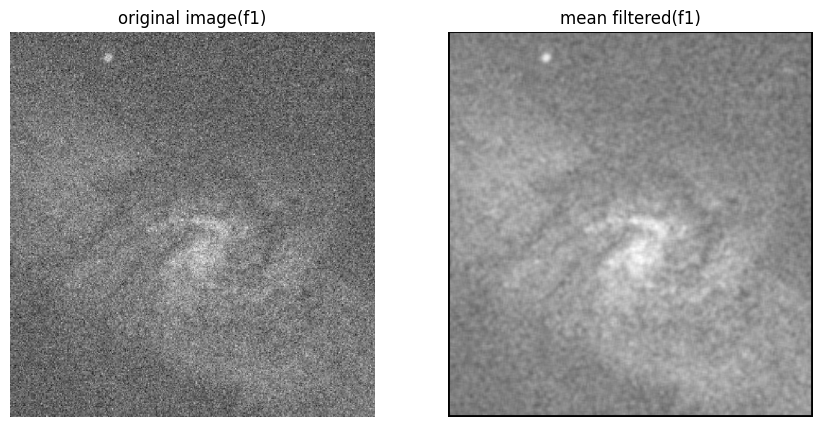

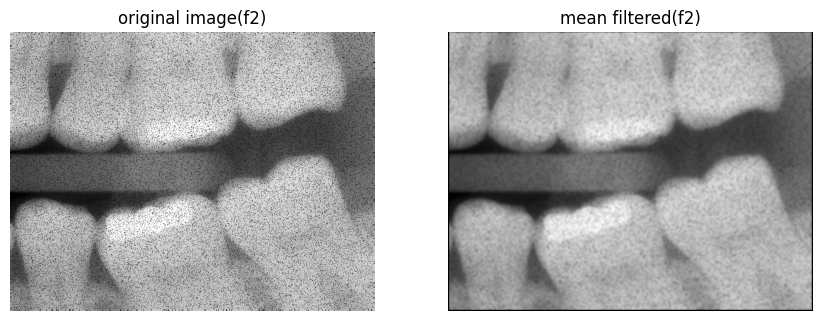

In [60]:
target = [f1, f2]

for f in range (target) :
  r_mean = np.zeros(np.shape(f))

  for x in range(ss,np.size(f,0)-ss):
    for y in range(ss,np.size(f,1)-ss):
      Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
      r_mean[x,y] = np.mean(Sxy)

  plt.figure(figsize=(16,9))
  plt.subplot(131)
  plt.imshow(f,cmap='gray',aspect='equal')
  plt.axis('off')
  plt.title('corrupted image')
  plt.subplot(132)
  plt.imshow(r_mean,cmap='gray',aspect='equal')
  plt.axis('off')
  plt.title('mean filtered')

2. Median

In [61]:
results = {}

for name, f in target:
    r_median = np.zeros(np.shape(f))
    for x in range(ss, np.size(f, 0) - ss):
        for y in range(ss, np.size(f, 1) - ss):
            Sxy = f[x - ss : x - ss + SS, y - ss : y - ss + SS]
            r_median[x, y] = np.median(Sxy)

    results[name] = {"original": f, "median": r_median}

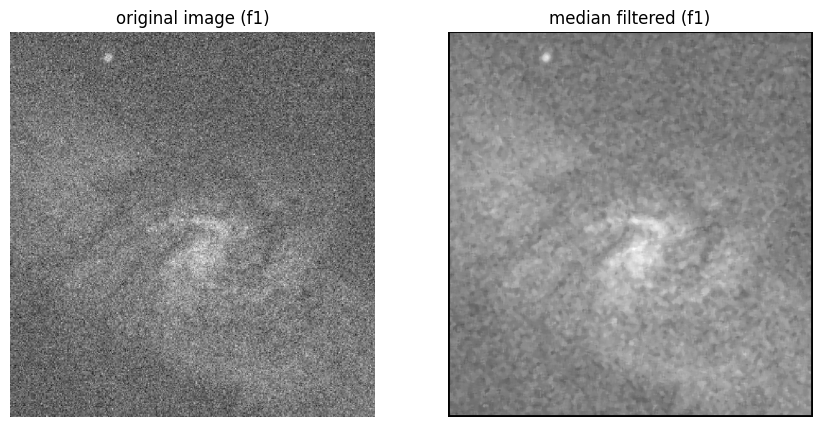

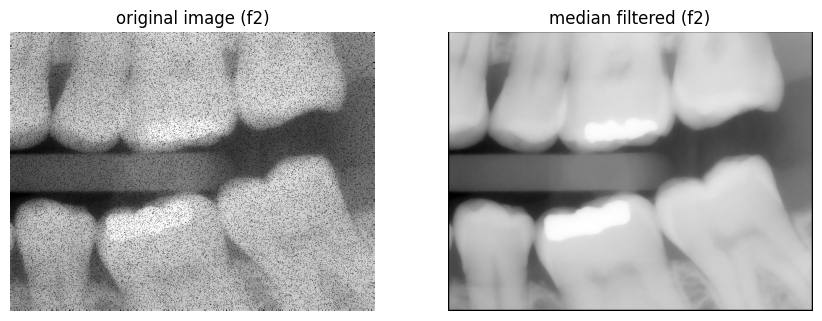

In [62]:
for name, data in results.items():
    plt.figure(figsize=(16, 9))

    plt.subplot(131)
    plt.imshow(data["original"], cmap="gray", aspect="equal")
    plt.axis("off")
    plt.title(f"original image ({name})")

    plt.subplot(132)
    plt.imshow(data["median"], cmap="gray", aspect="equal")
    plt.axis("off")
    plt.title(f"median filtered ({name})")

    plt.show()

3. Adaptive Local Noise Reduction

In [63]:
# Adaptive local noise reduction
results = {}

for name, f in target :
  std_eta = 16
  SS = 5

  ss = int((SS-1)/2)
  r_amean = np.zeros(np.shape(f))
  for x in range(ss,np.size(f,0)-ss):
    for y in range(ss,np.size(f,1)-ss):
      Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
      std_Sxy = np.std(Sxy)
      r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))
    results[name] = {"original": f, "Adaptive local": r_amean}

/tmp/ipykernel_539/1176200657.py:14: RuntimeWarning: divide by zero encountered in scalar divide
  r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))
/tmp/ipykernel_539/1176200657.py:14: RuntimeWarning: invalid value encountered in scalar multiply
  r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))


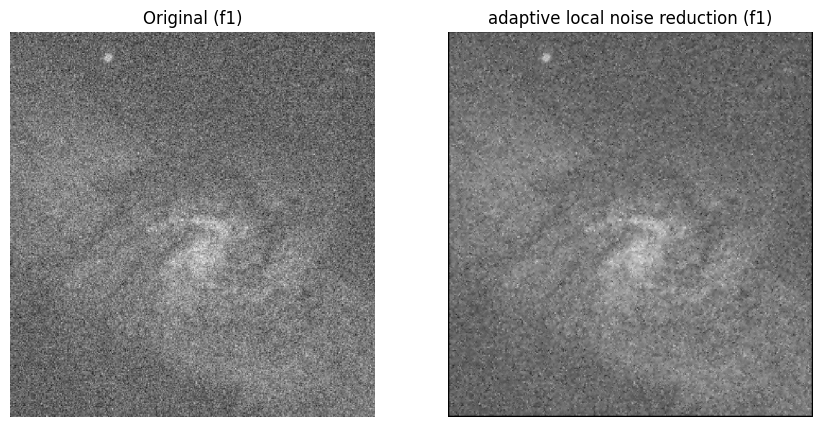

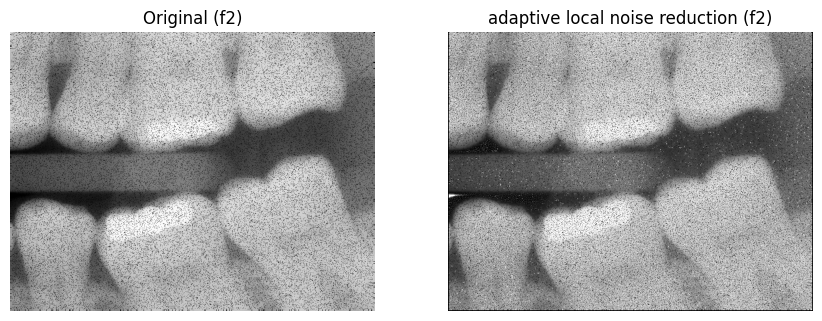

In [64]:
for name, data in results.items():
    plt.figure(figsize=(16, 9))

    plt.subplot(131)
    plt.imshow(data["original"], cmap="gray", aspect="equal", vmin=0, vmax=255)
    plt.axis("off")
    plt.title(f"Original ({name})")

    plt.subplot(132)
    plt.imshow(
        data["Adaptive local"], cmap="gray", aspect="equal", vmin=0, vmax=255
    )
    plt.axis("off")
    plt.title(f"adaptive local noise reduction ({name})")

    plt.show()

- 복원된 f1, f2를 그림파일로 저장하기

In [65]:
plt.imsave(
    "denoised-galaxy-pair.png", results["f1"]["Adaptive local"], cmap="gray"
)
plt.imsave(
    "denoised-dentalXray.png", results["f2"]["Adaptive local"], cmap="gray"
)